In [1]:
import numpy as np
import random
import pandas as pd
from tqdm import tqdm
import os
import matplotlib.pyplot as plt
from pathlib import Path

# Set professional style for all plots
plt.style.use('seaborn-v0_8')  # Use a clean style
plt.rcParams.update({
    'font.size': 12,
    'font.family': 'sans-serif',
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.titlesize': 18,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# Define consistent color palettes
colors_age = ['#1f77b4', '#ff7f0e', '#2ca02c']  # Blue, Orange, Green for 0-19, 20-64, 65+
colors_tfr = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # Blue, Orange, Green, Red for TFRs
colors_change = ['#d62728', '#2ca02c']  # Red for decrease, Green for increase


In [2]:
data = Path("data")

In [3]:
datafiler = os.listdir(data)
datafiler.sort()
datafiler

['befolkning.csv',
 'befolkningsutvikling_2023_2073_1_1-1_66-2_1.csv',
 'befolkningsutvikling_2023_2123_1_1-1_66-2_1.csv',
 'dodelighet_2023.csv',
 'netto_overføring.csv',
 'netto_overføring.xlsx',
 'netto_overføring_2024.csv',
 'oljefondets_utvikling.csv',
 'oljefondets_uvtikling.xls',
 'popfordeling_2023-2073_tfr1_1.csv',
 'popfordeling_2023-2073_tfr1_66.csv',
 'popfordeling_2023-2073_tfr2_1.csv',
 'popfordeling_2023-2123_tfr1_1.csv',
 'popfordeling_2023-2123_tfr1_66.csv',
 'popfordeling_2023-2123_tfr2_1.csv',
 'populasjon_2073_tfr1_1.csv',
 'populasjon_2073_tfr1_66.csv',
 'populasjon_2073_tfr2_1.csv',
 'populasjon_2123_tfr1_1.csv',
 'populasjon_2123_tfr1_66.csv',
 'populasjon_2123_tfr2_1.csv',
 'startpop_no.csv']

In [4]:
aktuelle_aar = 2073
aar = 2025
alder = 27
print(f"I året {aktuelle_aar} er jeg {aktuelle_aar - aar + alder} år gammel")

I året 2073 er jeg 75 år gammel


In [5]:
befolkning_23_63 = pd.read_csv(data / f"befolkningsutvikling_2023_{aktuelle_aar}_1_1-1_66-2_1.csv")
befolkning_23_63.tail(5)

,år,pop_1.1,pop_1.66,pop_2.1
46,2069,4038312,4717072,5300813
47,2070,3985041,4685341,5292501
48,2071,3931218,4653681,5283672
49,2072,3877527,4621357,5275614
50,2073,3823431,4589615,5266862


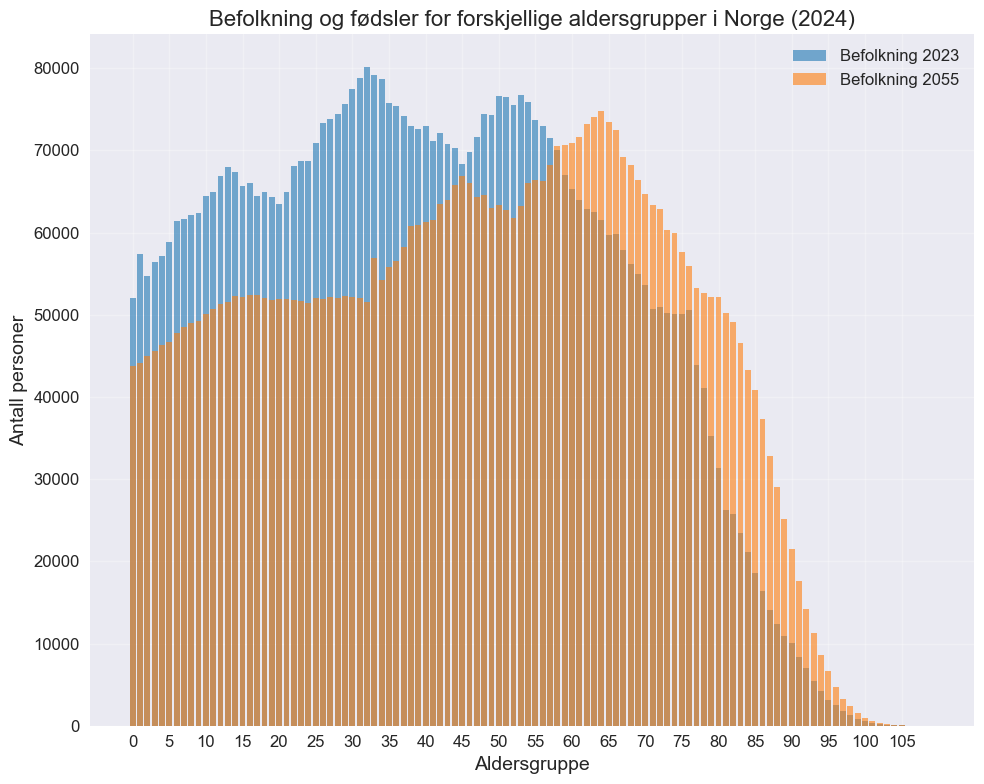

In [6]:
pop = pd.read_csv(data / 'popfordeling_2023-2073_tfr1_66.csv').iloc[:,:93]

year_from = 2023
year_to =  2023 + 32

pop = pop[["sex","alder", f"pop_{year_from}", f"pop_{year_to}"]]

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))
pop_total = pop.groupby("alder")[["pop_2023", "pop_2055"]].sum().reset_index()

ax.bar(pop_total.index, pop_total[f"pop_{year_from}"], color=colors_tfr[0], alpha=0.6, label='Befolkning 2023')
ax.bar(pop_total.index, pop_total[f"pop_{year_to}"], color=colors_tfr[1], alpha=0.6, label='Befolkning 2055')



ax.set_ylabel('Antall personer')
ax.set_xlabel('Aldersgruppe')
ax.set_title('Befolkning og fødsler for forskjellige aldersgrupper i Norge (2024)')
ax.legend()

# Customizing the x-axis
ax.set_xticks(range(0, len(pop_total.index), 5))
ax.set_xticklabels(range(0, len(pop_total.index), 5))

plt.tight_layout()


In [7]:
pop

,sex,alder,pop_2023,pop_2055
0,K,0,25310.0,21401.0
1,K,1,28037.0,21549.0
2,K,2,26820.0,21764.0
3,K,3,27466.0,22412.0
4,K,4,27692.0,22546.0
...,...,...,...,...
215,M,105,28.0,20.0
216,M,106,NaN,NaN
217,M,107,NaN,NaN
218,M,108,NaN,NaN


In [8]:
oljefondet = pd.read_csv("data/oljefondets_utvikling.csv", delimiter=";")
cols = ["år", "kronekurs", "avkastning", "tilførsel", "totalt"]
oljefondet.columns = cols

oljefondet[["kronekurs", "avkastning", "tilførsel", "totalt"]] = oljefondet[["kronekurs", "avkastning", "tilførsel", "totalt"]] * 1e9
oljefondet

,år,kronekurs,avkastning,tilførsel,totalt
0,1998,1.833000e+10,1.220000e+10,1.413100e+11,1.720000e+11
1,1999,2.124000e+10,3.544000e+10,1.657300e+11,2.220000e+11
2,2000,2.952000e+10,4.133000e+10,3.156000e+11,3.860000e+11
3,2001,1.409000e+10,3.274000e+10,5.668600e+11,6.140000e+11
4,2002,-8.656000e+10,3.320000e+09,6.922400e+11,6.090000e+11
5,2003,-4.574000e+10,9.490000e+10,7.961500e+11,8.450000e+11
6,2004,-9.490000e+10,1.769800e+11,9.343200e+11,1.016000e+12
7,2005,-5.923000e+10,3.036700e+11,1.154610e+12,1.399000e+12
8,2006,-8.705000e+10,4.278300e+11,1.442910e+12,1.784000e+12
9,2007,-2.405500e+11,5.026400e+11,1.756560e+12,2.019000e+12


In [9]:
oljefondet["totalt"]

0     1.720000e+11
1     2.220000e+11
2     3.860000e+11
3     6.140000e+11
4     6.090000e+11
5     8.450000e+11
6     1.016000e+12
7     1.399000e+12
8     1.784000e+12
9     2.019000e+12
10    2.275000e+12
11    2.640000e+12
12    3.077000e+12
13    3.312000e+12
14    3.816000e+12
15    5.038000e+12
16    6.431000e+12
17    7.475000e+12
18    7.510000e+12
19    8.488000e+12
20    8.256000e+12
21    1.008800e+13
22    1.091400e+13
23    1.234000e+13
24    1.242900e+13
25    1.575700e+13
26    1.974200e+13
27    2.126800e+13
Name: totalt, dtype: float64

In [10]:
(oljefondet["totalt"] / 5.7e6)

0     3.017544e+04
1     3.894737e+04
2     6.771930e+04
3     1.077193e+05
4     1.068421e+05
5     1.482456e+05
6     1.782456e+05
7     2.454386e+05
8     3.129825e+05
9     3.542105e+05
10    3.991228e+05
11    4.631579e+05
12    5.398246e+05
13    5.810526e+05
14    6.694737e+05
15    8.838596e+05
16    1.128246e+06
17    1.311404e+06
18    1.317544e+06
19    1.489123e+06
20    1.448421e+06
21    1.769825e+06
22    1.914737e+06
23    2.164912e+06
24    2.180526e+06
25    2.764386e+06
26    3.463509e+06
27    3.731228e+06
Name: totalt, dtype: float64

In [11]:
20_000_000_000 / 5_700_000

3508.7719298245615

<Axes: xlabel='år'>

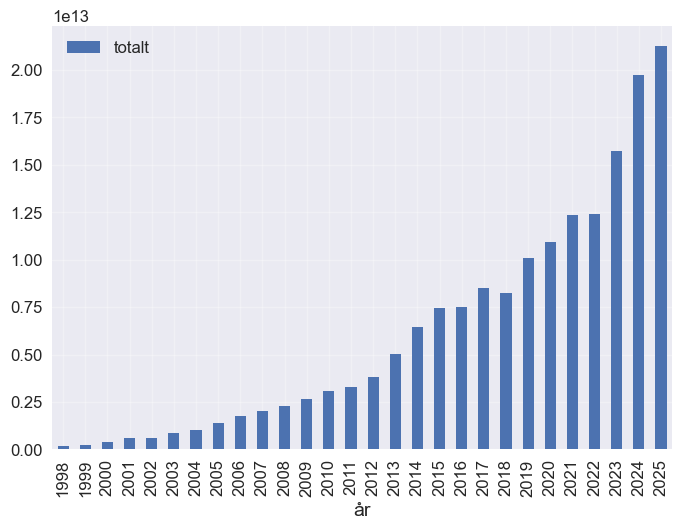

In [12]:
oljefondet.plot(x="år", y="totalt", kind="bar")

In [13]:
oljefondet

,år,kronekurs,avkastning,tilførsel,totalt
0,1998,1.833000e+10,1.220000e+10,1.413100e+11,1.720000e+11
1,1999,2.124000e+10,3.544000e+10,1.657300e+11,2.220000e+11
2,2000,2.952000e+10,4.133000e+10,3.156000e+11,3.860000e+11
3,2001,1.409000e+10,3.274000e+10,5.668600e+11,6.140000e+11
4,2002,-8.656000e+10,3.320000e+09,6.922400e+11,6.090000e+11
5,2003,-4.574000e+10,9.490000e+10,7.961500e+11,8.450000e+11
6,2004,-9.490000e+10,1.769800e+11,9.343200e+11,1.016000e+12
7,2005,-5.923000e+10,3.036700e+11,1.154610e+12,1.399000e+12
8,2006,-8.705000e+10,4.278300e+11,1.442910e+12,1.784000e+12
9,2007,-2.405500e+11,5.026400e+11,1.756560e+12,2.019000e+12


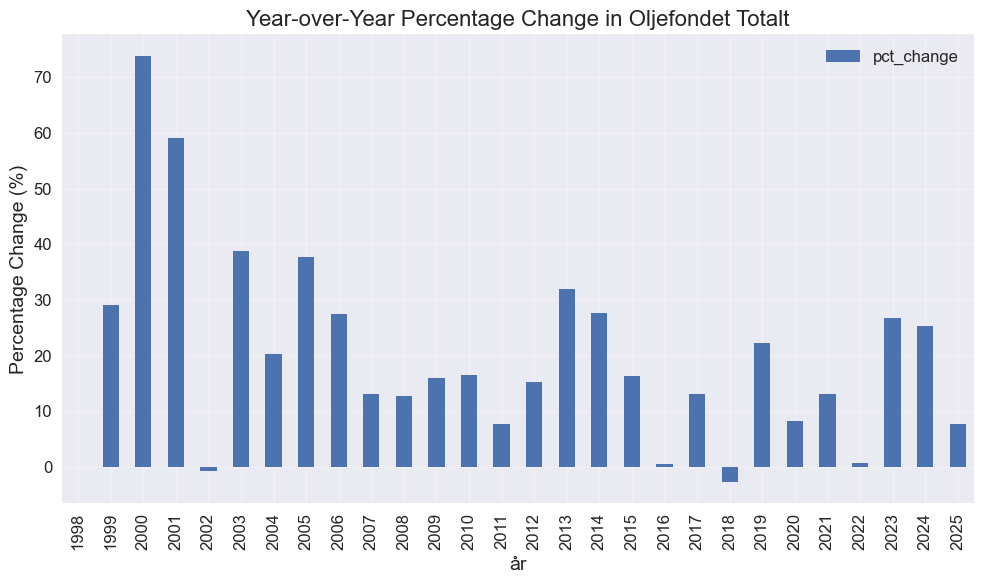

In [14]:
# Calculate year-over-year percentage change in 'totalt'
oljefondet['pct_change'] = oljefondet['totalt'].pct_change() * 100

# Plot the percentage change
oljefondet.plot(x="år", y="pct_change", kind="bar", figsize=(10, 6))
plt.ylabel('Percentage Change (%)')
plt.title('Year-over-Year Percentage Change in Oljefondet Totalt')
plt.grid(True, alpha=0.3)
plt.tight_layout()

In [15]:
# netto overføring
netto_overforing = pd.read_csv("data/netto_overføring_2024.csv", delimiter=";")
netto_overforing
netto_overforing = netto_overforing.iloc[:, 0:2]
netto_overforing
netto_overforing.columns = ["alder", "netto_overforing"]
netto_overforing

,alder,netto_overforing
0,0,260.089686
1,1,360.538117
2,2,371.300448
3,3,425.112108
4,4,346.188341
...,...,...
105,105,1648.430493
106,106,1648.430493
107,107,1648.430493
108,108,1648.430493


In [16]:
pop_total = pd.read_csv(data / 'popfordeling_2023-2073_tfr1_66.csv').iloc[:,:93]
pop_total_m_overforing = pop_total.merge(netto_overforing, on="alder")

for year in range(2023, 2074):
    pop_total_m_overforing[f"pop_{year}"] = (pop_total_m_overforing[f"pop_{year}"] * pop_total_m_overforing["netto_overforing"]).fillna(0) * 1000


In [17]:
pop_total_m_overforing

,sex,alder,pop_2023,pop_2024,pop_2025,pop_2026,pop_2027,pop_2028,pop_2029,pop_2030,...,pop_2065,pop_2066,pop_2067,pop_2068,pop_2069,pop_2070,pop_2071,pop_2072,pop_2073,netto_overforing
0,K,0,6.582870e+09,6.638009e+09,6.672081e+09,6.648933e+09,6.650493e+09,6.596655e+09,6.611740e+09,6.639049e+09,...,5.306870e+09,5.343543e+09,5.365650e+09,5.309731e+09,5.259794e+09,5.281381e+09,5.218700e+09,5.163040e+09,5.105821e+09,260.089686
1,K,1,1.010841e+10,9.115485e+09,9.187953e+09,9.236987e+09,9.207783e+09,9.211028e+09,9.136757e+09,9.156587e+09,...,7.353896e+09,7.350291e+09,7.400405e+09,7.431051e+09,7.348127e+09,7.284673e+09,7.312074e+09,7.226265e+09,7.150192e+09,360.538117
2,K,2,9.958278e+09,1.040607e+10,9.386475e+09,9.459993e+09,9.511232e+09,9.481157e+09,9.483756e+09,9.407268e+09,...,7.576757e+09,7.571187e+09,7.568588e+09,7.620570e+09,7.651388e+09,7.565618e+09,7.500640e+09,7.528488e+09,7.440118e+09,371.300448
3,K,3,1.167613e+10,1.139768e+10,1.191249e+10,1.074556e+10,1.083101e+10,1.088797e+10,1.085354e+10,1.085779e+10,...,8.661659e+09,8.673562e+09,8.667186e+09,8.664210e+09,8.723300e+09,8.759435e+09,8.661234e+09,8.585564e+09,8.618723e+09,425.112108
4,K,4,9.586648e+09,9.506332e+09,9.280963e+09,9.700197e+09,8.749910e+09,8.818802e+09,8.865537e+09,8.837496e+09,...,7.094784e+09,7.053241e+09,7.062588e+09,7.057049e+09,7.054280e+09,7.103439e+09,7.132172e+09,7.052895e+09,6.990927e+09,346.188341
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
215,M,105,4.615605e+07,6.593722e+06,1.648430e+07,9.890583e+06,1.153901e+07,8.242152e+06,9.890583e+06,3.296861e+06,...,3.956233e+07,2.307803e+07,2.472646e+07,3.296861e+07,1.648430e+07,2.967175e+07,2.967175e+07,3.461704e+07,3.626547e+07,1648.430493
216,M,106,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1648.430493
217,M,107,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1648.430493
218,M,108,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1648.430493


In [18]:
pop_sum = pop_total_m_overforing[[f"pop_{year}" for year in range(2023, 2074)]].sum().reset_index()
pop_sum.columns = ["aar", "sum_overforing"]

In [19]:
pop_sum["aar"] = range(2023,2074)
pop_sum

,aar,sum_overforing
0,2023,3.054526e+11
1,2024,3.135237e+11
2,2025,3.224936e+11
3,2026,3.319720e+11
4,2027,3.422034e+11
5,2028,3.528834e+11
6,2029,3.637235e+11
7,2030,3.753512e+11
8,2031,3.870558e+11
9,2032,3.991852e+11


<Axes: xlabel='aar'>

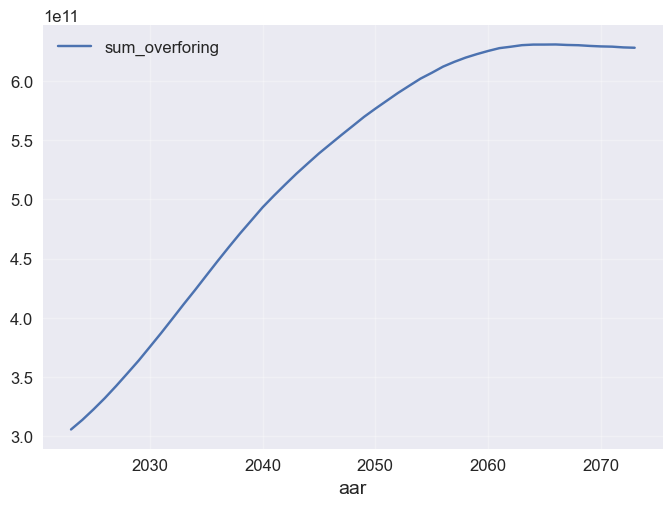

In [20]:
pop_sum.plot(x="aar", y="sum_overforing")


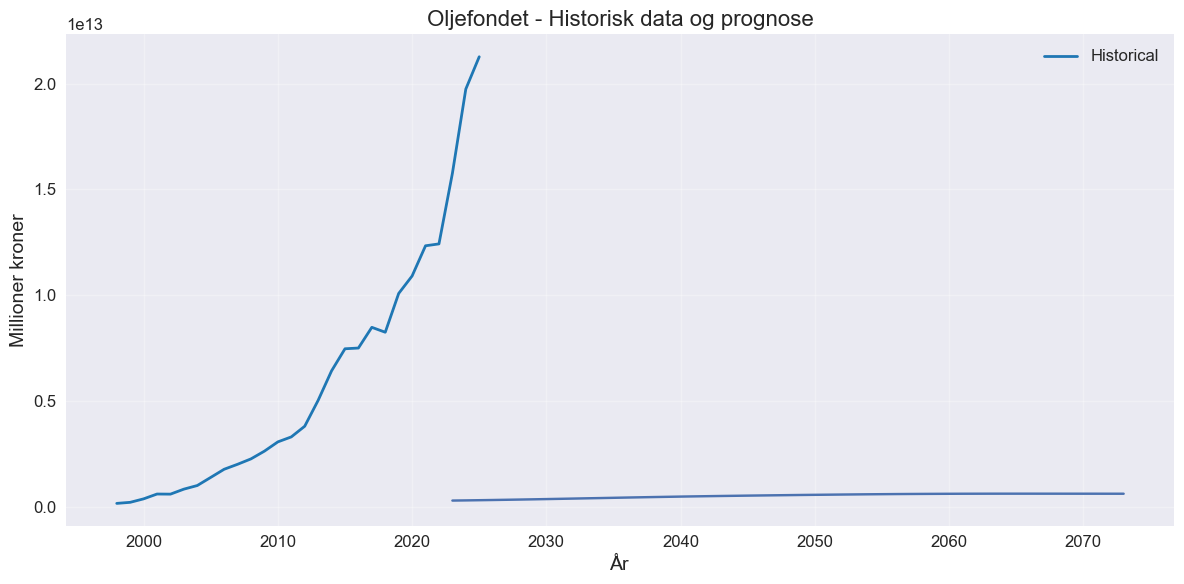

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(oljefondet['år'], oljefondet['totalt'], label='Historical', color=colors_tfr[0], linewidth=2)
# ax.plot(forecast_df['år'], forecast_df['totalt'], label='Forecast', color=colors_tfr[1], linewidth=2, linestyle='--')
ax.plot(pop_sum["aar"], pop_sum["sum_overforing"])
ax.set_xlabel('År')
ax.set_ylabel('Millioner kroner')
ax.set_title('Oljefondet - Historisk data og prognose')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()

In [22]:
pop_total_m_overforing["netto_overforing_2023_millioner"] = (
    (pop_total_m_overforing["pop_2023"] * pop_total_m_overforing["netto_overforing"])
    /1e3
)

pop_total_m_overforing["netto_overforing_2055_millioner"] = (
    (pop_total_m_overforing["pop_2055"] * pop_total_m_overforing["netto_overforing"])
    /1e3
)

In [23]:
pop_total_m_overforing.to_clipboard()

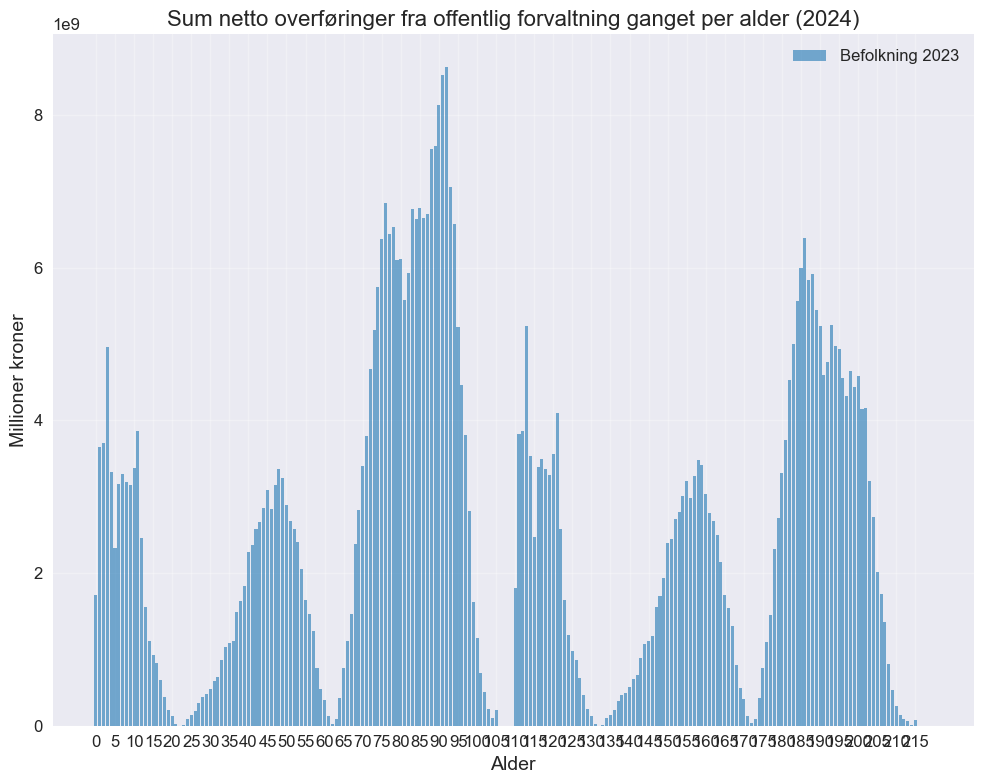

In [24]:

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))


ax.bar(pop_total_m_overforing.index, pop_total_m_overforing[f"netto_overforing_2023_millioner"], color=colors_tfr[0], alpha=0.6, label='Befolkning 2023')



ax.set_ylabel('Millioner kroner')
ax.set_xlabel('Alder')
ax.set_title('Sum netto overføringer fra offentlig forvaltning ganget per alder (2024)')
ax.legend()

# Customizing the x-axis
ax.set_xticks(range(0, len(pop_total_m_overforing.index), 5))
ax.set_xticklabels(range(0, len(pop_total_m_overforing.index), 5))

plt.tight_layout()

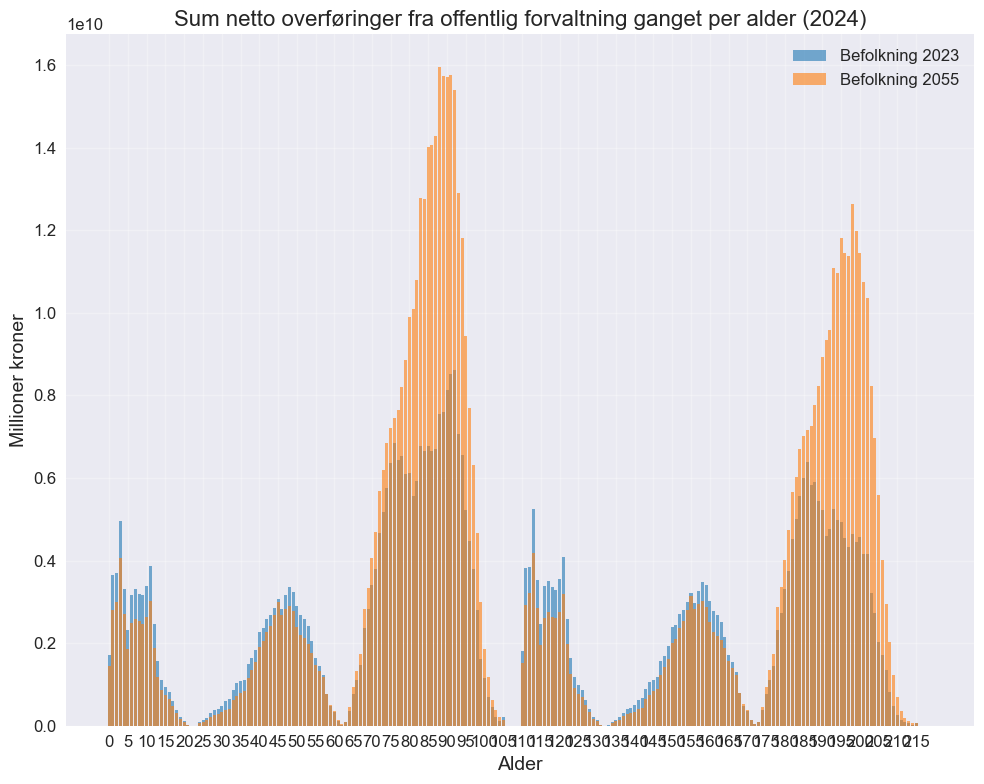

In [25]:

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))


ax.bar(pop_total_m_overforing.index, pop_total_m_overforing[f"netto_overforing_2023_millioner"], color=colors_tfr[0], alpha=0.6, label='Befolkning 2023')
ax.bar(pop_total_m_overforing.index, pop_total_m_overforing[f"netto_overforing_2055_millioner"], color=colors_tfr[1], alpha=0.6, label='Befolkning 2055')



ax.set_ylabel('Millioner kroner')
ax.set_xlabel('Alder')
ax.set_title('Sum netto overføringer fra offentlig forvaltning ganget per alder (2024)')
ax.legend()

# Customizing the x-axis
ax.set_xticks(range(0, len(pop_total_m_overforing.index), 5))
ax.set_xticklabels(range(0, len(pop_total_m_overforing.index), 5))

plt.tight_layout()

In [26]:
pop_total_m_overforing["diff"] = pop_total_m_overforing["netto_overforing_2055_millioner"] - pop_total_m_overforing["netto_overforing_2023_millioner"]
pop_total_m_overforing

,sex,alder,pop_2023,pop_2024,pop_2025,pop_2026,pop_2027,pop_2028,pop_2029,pop_2030,...,pop_2068,pop_2069,pop_2070,pop_2071,pop_2072,pop_2073,netto_overforing,netto_overforing_2023_millioner,netto_overforing_2055_millioner,diff
0,K,0,6.582870e+09,6.638009e+09,6.672081e+09,6.648933e+09,6.650493e+09,6.596655e+09,6.611740e+09,6.639049e+09,...,5.309731e+09,5.259794e+09,5.281381e+09,5.218700e+09,5.163040e+09,5.105821e+09,260.089686,1.712137e+09,1.447706e+09,-2.644307e+08
1,K,1,1.010841e+10,9.115485e+09,9.187953e+09,9.236987e+09,9.207783e+09,9.211028e+09,9.136757e+09,9.156587e+09,...,7.431051e+09,7.348127e+09,7.284673e+09,7.312074e+09,7.226265e+09,7.150192e+09,360.538117,3.644466e+09,2.801106e+09,-8.433604e+08
2,K,2,9.958278e+09,1.040607e+10,9.386475e+09,9.459993e+09,9.511232e+09,9.481157e+09,9.483756e+09,9.407268e+09,...,7.620570e+09,7.651388e+09,7.565618e+09,7.500640e+09,7.528488e+09,7.440118e+09,371.300448,3.697513e+09,3.000473e+09,-6.970405e+08
3,K,3,1.167613e+10,1.139768e+10,1.191249e+10,1.074556e+10,1.083101e+10,1.088797e+10,1.085354e+10,1.085779e+10,...,8.664210e+09,8.723300e+09,8.759435e+09,8.661234e+09,8.585564e+09,8.618723e+09,425.112108,4.963664e+09,4.050303e+09,-9.133604e+08
4,K,4,9.586648e+09,9.506332e+09,9.280963e+09,9.700197e+09,8.749910e+09,8.818802e+09,8.865537e+09,8.837496e+09,...,7.057049e+09,7.054280e+09,7.103439e+09,7.132172e+09,7.052895e+09,6.990927e+09,346.188341,3.318786e+09,2.702056e+09,-6.167294e+08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
215,M,105,4.615605e+07,6.593722e+06,1.648430e+07,9.890583e+06,1.153901e+07,8.242152e+06,9.890583e+06,3.296861e+06,...,3.296861e+07,1.648430e+07,2.967175e+07,2.967175e+07,3.461704e+07,3.626547e+07,1648.430493,7.608505e+07,5.434646e+07,-2.173858e+07
216,M,106,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1648.430493,0.000000e+00,0.000000e+00,0.000000e+00
217,M,107,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1648.430493,0.000000e+00,0.000000e+00,0.000000e+00
218,M,108,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1648.430493,0.000000e+00,0.000000e+00,0.000000e+00


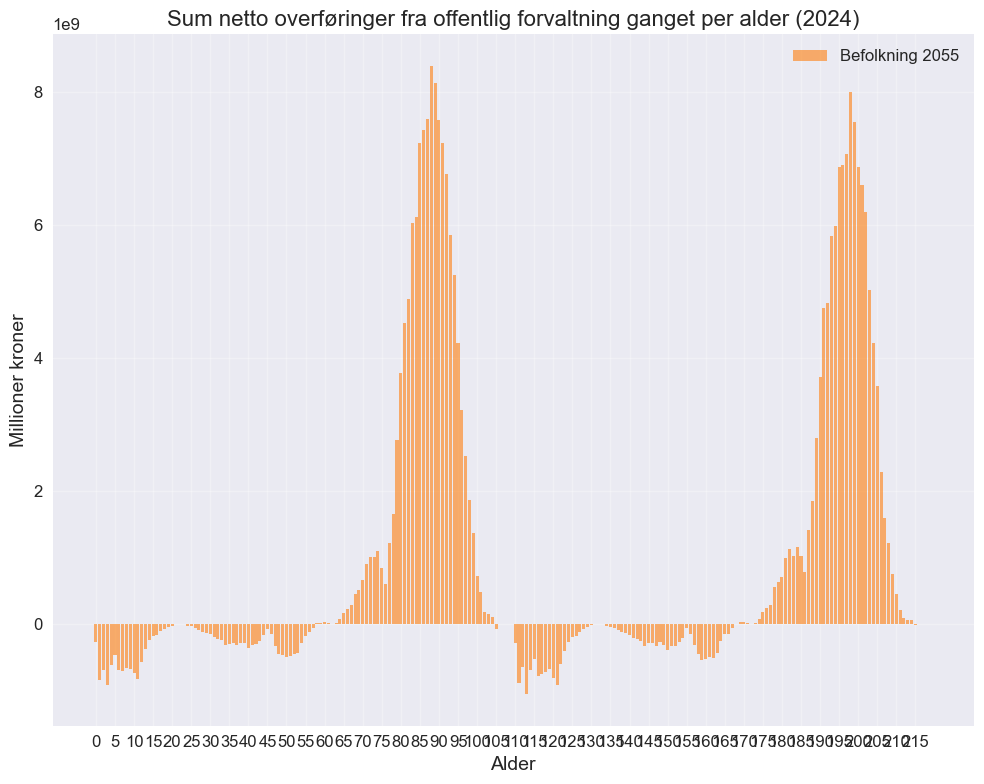

In [27]:

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))

ax.bar(pop_total_m_overforing.index, pop_total_m_overforing[f"diff"], color=colors_tfr[1], alpha=0.6, label='Befolkning 2055')


ax.set_ylabel('Millioner kroner')
ax.set_xlabel('Alder')
ax.set_title('Sum netto overføringer fra offentlig forvaltning ganget per alder (2024)')
ax.legend()

# Customizing the x-axis
ax.set_xticks(range(0, len(pop_total_m_overforing.index), 5))
ax.set_xticklabels(range(0, len(pop_total_m_overforing.index), 5))

plt.tight_layout()

In [28]:
# Sum of negative values and positive values in netto_overforing_2055_millioner
negative_sum = pop_total_m_overforing.loc[lambda x: x["netto_overforing_2023_millioner"] < 0, "netto_overforing_2023_millioner"].sum()
positive_sum = pop_total_m_overforing.loc[lambda x: x["netto_overforing_2023_millioner"] > 0, "netto_overforing_2023_millioner"].sum()

print(f"Sum of negative values: {round(negative_sum,2)}")
print(f"Sum of positive values: {round(positive_sum,2)}")
print(round(-negative_sum / positive_sum,2) * 100, "%")

Sum of negative values: 0.0
Sum of positive values: 543884096167.67
-0.0 %


In [29]:
# Sum of negative values and positive values in netto_overforing_2055_millioner
negative_sum = pop_total_m_overforing.loc[lambda x: x["netto_overforing_2055_millioner"] < 0, "netto_overforing_2055_millioner"].sum()
positive_sum = pop_total_m_overforing.loc[lambda x: x["netto_overforing_2055_millioner"] > 0, "netto_overforing_2055_millioner"].sum()

print(f"Sum of negative values: {round(negative_sum,2)}")
print(f"Sum of positive values: {round(positive_sum,2)}")
print(round(-negative_sum / positive_sum,2) * 100, "%")

Sum of negative values: 0.0
Sum of positive values: 746770710372.71
-0.0 %


In [30]:
pop_total_m_overforing

,sex,alder,pop_2023,pop_2024,pop_2025,pop_2026,pop_2027,pop_2028,pop_2029,pop_2030,...,pop_2068,pop_2069,pop_2070,pop_2071,pop_2072,pop_2073,netto_overforing,netto_overforing_2023_millioner,netto_overforing_2055_millioner,diff
0,K,0,6.582870e+09,6.638009e+09,6.672081e+09,6.648933e+09,6.650493e+09,6.596655e+09,6.611740e+09,6.639049e+09,...,5.309731e+09,5.259794e+09,5.281381e+09,5.218700e+09,5.163040e+09,5.105821e+09,260.089686,1.712137e+09,1.447706e+09,-2.644307e+08
1,K,1,1.010841e+10,9.115485e+09,9.187953e+09,9.236987e+09,9.207783e+09,9.211028e+09,9.136757e+09,9.156587e+09,...,7.431051e+09,7.348127e+09,7.284673e+09,7.312074e+09,7.226265e+09,7.150192e+09,360.538117,3.644466e+09,2.801106e+09,-8.433604e+08
2,K,2,9.958278e+09,1.040607e+10,9.386475e+09,9.459993e+09,9.511232e+09,9.481157e+09,9.483756e+09,9.407268e+09,...,7.620570e+09,7.651388e+09,7.565618e+09,7.500640e+09,7.528488e+09,7.440118e+09,371.300448,3.697513e+09,3.000473e+09,-6.970405e+08
3,K,3,1.167613e+10,1.139768e+10,1.191249e+10,1.074556e+10,1.083101e+10,1.088797e+10,1.085354e+10,1.085779e+10,...,8.664210e+09,8.723300e+09,8.759435e+09,8.661234e+09,8.585564e+09,8.618723e+09,425.112108,4.963664e+09,4.050303e+09,-9.133604e+08
4,K,4,9.586648e+09,9.506332e+09,9.280963e+09,9.700197e+09,8.749910e+09,8.818802e+09,8.865537e+09,8.837496e+09,...,7.057049e+09,7.054280e+09,7.103439e+09,7.132172e+09,7.052895e+09,6.990927e+09,346.188341,3.318786e+09,2.702056e+09,-6.167294e+08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
215,M,105,4.615605e+07,6.593722e+06,1.648430e+07,9.890583e+06,1.153901e+07,8.242152e+06,9.890583e+06,3.296861e+06,...,3.296861e+07,1.648430e+07,2.967175e+07,2.967175e+07,3.461704e+07,3.626547e+07,1648.430493,7.608505e+07,5.434646e+07,-2.173858e+07
216,M,106,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1648.430493,0.000000e+00,0.000000e+00,0.000000e+00
217,M,107,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1648.430493,0.000000e+00,0.000000e+00,0.000000e+00
218,M,108,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1648.430493,0.000000e+00,0.000000e+00,0.000000e+00


In [31]:
pop

,sex,alder,pop_2023,pop_2055
0,K,0,25310.0,21401.0
1,K,1,28037.0,21549.0
2,K,2,26820.0,21764.0
3,K,3,27466.0,22412.0
4,K,4,27692.0,22546.0
...,...,...,...,...
215,M,105,28.0,20.0
216,M,106,NaN,NaN
217,M,107,NaN,NaN
218,M,108,NaN,NaN


In [32]:
# Function to calculate netto_overforing_pct for a given population dataframe
def calculate_netto_overforing_pct(pop_df, netto_overforing_rates):
    # Aggregate pop by age (summing over sex)
    pop_agg = pop_df.groupby("alder").sum().reset_index()
    
    # Merge with netto_overforing rates
    pop_merged = pop_agg.merge(netto_overforing_rates, on="alder")
    
    # Generate netto_overforing columns for all years
    for aar in range(2023, 2074):
        pop_col = f"pop_{aar}"
        res_col = f"netto_overforing_{aar}_millioner"
        
        if pop_col in pop_merged.columns:
            pop_merged[res_col] = (pop_merged[pop_col] * pop_merged["netto_overforing"]) / 1e3
    
    # Calculate the sums and percentages
    netto_overforing_pct = pd.DataFrame(columns=["aar", "negativ_sum", "positiv_sum", "prosent"])
    
    for aar in range(2023, 2074):
        col_name = f"netto_overforing_{aar}_millioner"
        
        if col_name in pop_merged.columns:
            negative_sum = pop_merged.loc[lambda x: x[col_name] < 0, col_name].sum()
            positive_sum = pop_merged.loc[lambda x: x[col_name] > 0, col_name].sum()
            
            prosent = round(-negative_sum / positive_sum, 2) * 100 if positive_sum != 0 else 0
            
            new_row = pd.DataFrame([{
                "aar": aar,
                "negativ_sum": round(negative_sum, 2),
                "positiv_sum": round(positive_sum, 2),
                "prosent": prosent
            }])
            netto_overforing_pct = pd.concat([netto_overforing_pct, new_row], ignore_index=True)
    
    return netto_overforing_pct

# Calculate for all three dataframes
netto_overforing_pct_1 = calculate_netto_overforing_pct(pop_1, netto_overforing)
netto_overforing_pct_2 = calculate_netto_overforing_pct(pop_2, netto_overforing)
netto_overforing_pct_3 = calculate_netto_overforing_pct(pop_3, netto_overforing)

# Add labels for each TFR scenario
netto_overforing_pct_1["tfr"] = "TFR 1.66"
netto_overforing_pct_2["tfr"] = "TFR 2.1"
netto_overforing_pct_3["tfr"] = "TFR 1.1"

# Combine all three
netto_overforing_all = pd.concat([netto_overforing_pct_1, netto_overforing_pct_2, netto_overforing_pct_3], ignore_index=True)
netto_overforing_all


NameError: name 'pop_1' is not defined

In [33]:
netto_overforing_all.loc[lambda x: x.tfr == "TFR 1.66"]


NameError: name 'netto_overforing_all' is not defined

NameError: name 'netto_overforing_all' is not defined

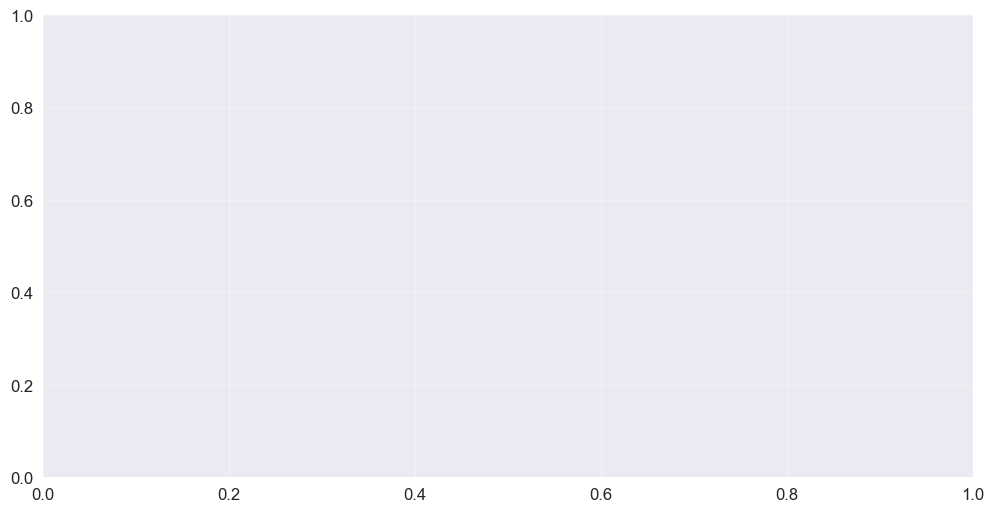

In [34]:
fig, ax = plt.subplots(figsize=(12, 6))

for tfr, color in zip(["TFR 1.66", "TFR 1.1", "TFR 2.1"], [colors_tfr[2], colors_tfr[3], colors_tfr[1]]):
    data = netto_overforing_all.loc[lambda x: x["tfr"] == tfr]
    ax.plot(data["aar"], data["prosent"], label=tfr, color=color, linewidth=2)

ax.set_xlabel('År')
ax.set_ylabel('Prosent')
ax.set_title('Netto overføring prosent per TFR-scenario')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 70)

plt.tight_layout()
plt.show()


In [35]:
data["negativ_sum"] + data["positiv_sum"]

TypeError: 'PosixPath' object is not subscriptable

NameError: name 'netto_overforing_all' is not defined

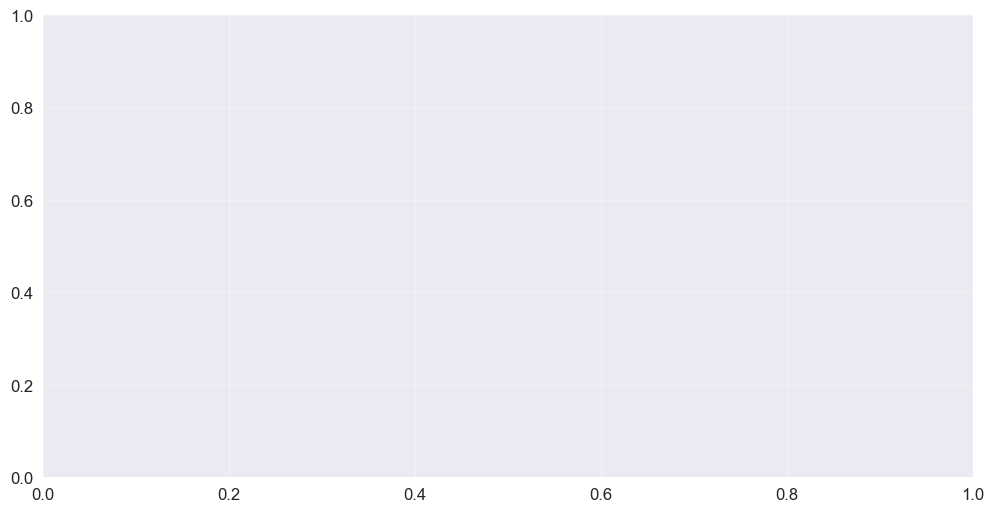

In [36]:
fig, ax = plt.subplots(figsize=(12, 6))

for tfr, color in zip(["TFR 2.1", "TFR 1.1", "TFR 1.66",], [colors_tfr[2], colors_tfr[3], colors_tfr[1]]):
    data = netto_overforing_all.loc[lambda x: x["tfr"] == tfr]

    ax.plot(data["aar"], (data["negativ_sum"] + data["positiv_sum"] )*1e6, label=tfr, color=color, linewidth=2)

ax.set_xlabel('År')
ax.set_ylabel('Millioner kroner')
ax.set_title('Netto overføring prosent per TFR-scenario')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [37]:
pop_total_m_overforing.sum() * 1e6

TypeError: can't multiply sequence by non-int of type 'float'

In [38]:
pop_3

NameError: name 'pop_3' is not defined